<a href="https://colab.research.google.com/github/Asmodey-it/machine-navchannya/blob/main/%D0%9B%D0%914_%D0%9F%D0%B0%D0%BD%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_%D0%9C_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('https://raw.githubusercontent.com/amankharwal/Website-data/master/CarPrice.csv')

print(f"Кількість об'єктів (рядків): {df.shape[0]}")
print(f"Кількість ознак (стовпців): {df.shape[1]}")

print("\nНазви стовпців:")
print(df.columns.tolist())

print("\nТипи даних:")
print(df.dtypes)

target = 'price'
print(f"\nЦільова змінна: {target}")

print("\nОсновні статистичні характеристики числових ознак:")
display(df.describe())

Кількість об'єктів (рядків): 205
Кількість ознак (стовпців): 26

Назви стовпців:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
c

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [2]:
print("Кількість пропущених значень у стовпцях:")
print(df.isnull().sum())

df_check = df.drop(columns=['car_ID']) if 'car_ID' in df.columns else df
duplicates_count = df_check.duplicated().sum()
print(f"\nКількість повних дублікатів: {duplicates_count}")

print("\nКількість унікальних значень в ознаках:")
print(df.nunique())

Кількість пропущених значень у стовпцях:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

Кількість повних дублікатів: 0

Кількість унікальних значень в ознаках:
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44
carheight    

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [3]:
if 'car_ID' in df.columns:
    car_ids = df['car_ID'].copy()
    df = df.drop(columns=['car_ID'])
    print("Стовпець 'car_ID' успішно збережено та видалено з навчальних ознак.")
else:
    car_ids = pd.Series(range(len(df)))
    print("Стовпець 'car_ID' у датасеті відсутній, створено індексний рядок.")

Стовпець 'car_ID' успішно збережено та видалено з навчальних ознак.


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


Коефіцієнти асиметрії числових ознак:
compressionratio    2.591720
enginesize          1.933375
price               1.764644
horsepower          1.395006
wheelbase           1.042514
carwidth            0.897375
stroke             -0.684648
curbweight          0.676402
citympg             0.658838
highwaympg          0.536038
symboling           0.209525
carlength           0.154810
peakrpm             0.074608
carheight           0.062660
boreratio           0.020009
dtype: float64


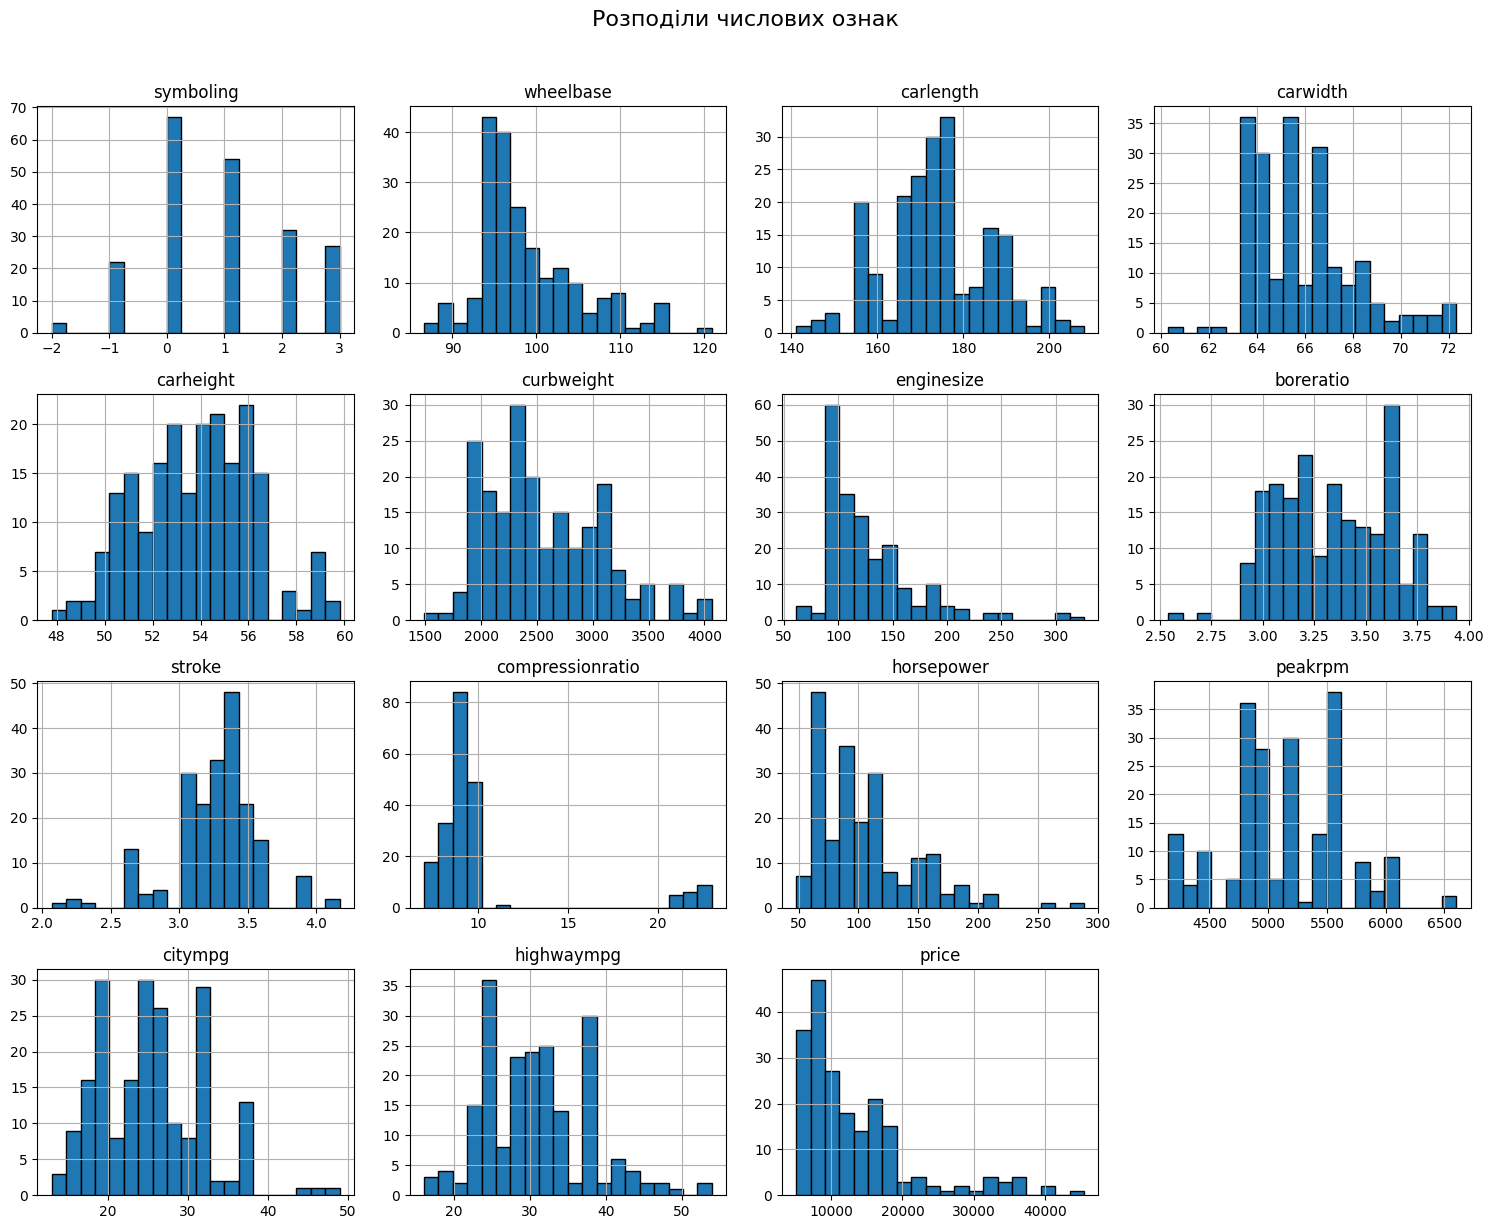

In [4]:
from scipy.stats import skew

numeric_features = df.select_dtypes(include=[np.number]).columns.tolist()

print("Коефіцієнти асиметрії числових ознак:")
skewness = df[numeric_features].apply(lambda x: skew(x.dropna()))
print(skewness.sort_values(key=abs, ascending=False))

df[numeric_features].hist(bins=20, figsize=(15, 12), edgecolor='black')
plt.suptitle("Розподіли числових ознак", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [5]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, car_ids, test_size=0.2, random_state=42
)

print(f"Розмір train вибірки: {X_train.shape}")
print(f"Розмір test вибірки: {X_test.shape}")

Розмір train вибірки: (164, 24)
Розмір test вибірки: (41, 24)


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [6]:
continuous_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
if 'symboling' in continuous_features:
    continuous_features.remove('symboling')

outlier_bounds = {}
print("Кількість потенційних викидів за методом IQR у train:")
for col in continuous_features:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_bounds[col] = (lower_bound, upper_bound)
    outliers_count = ((X_train[col] < lower_bound) | (X_train[col] > upper_bound)).sum()
    print(f"{col}: {outliers_count} викидів")

for col in continuous_features:
    lb, ub = outlier_bounds[col]
    X_train[col] = X_train[col].clip(lower=lb, upper=ub)
    X_test[col] = X_test[col].clip(lower=lb, upper=ub)

print("\nВикиди успішно опрацьовано шляхом обмеження меж.")

Кількість потенційних викидів за методом IQR у train:
wheelbase: 6 викидів
carlength: 0 викидів
carwidth: 10 викидів
carheight: 0 викидів
curbweight: 0 викидів
enginesize: 7 викидів
boreratio: 1 викидів
stroke: 16 викидів
compressionratio: 20 викидів
horsepower: 7 викидів
peakrpm: 2 викидів
citympg: 0 викидів
highwaympg: 1 викидів

Викиди успішно опрацьовано шляхом обмеження меж.


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


In [7]:
train_numeric = X_train.select_dtypes(include=[np.number])
corr_matrix = train_numeric.corr().abs()

upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
strong_corr_pairs = []
for col in upper_tri.columns:
    high_corr = upper_tri.index[upper_tri[col] > 0.85].tolist()
    for row in high_corr:
        strong_corr_pairs.append((row, col, corr_matrix.loc[row, col]))

print("Сильно корельовані пари (|r| > 0.85):")
for p in strong_corr_pairs:
    print(f"{p[0]} та {p[1]}: r = {p[2]:.3f}")

corrs_with_target = train_numeric.apply(lambda x: x.corr(y_train)).abs()
features_to_drop = set()
for row, col, _ in strong_corr_pairs:
    if row not in features_to_drop and col not in features_to_drop:
        if corrs_with_target[row] >= corrs_with_target[col]:
            features_to_drop.add(col)
        else:
            features_to_drop.add(row)

print(f"\nВидалені ознаки: {list(features_to_drop)}")

X_train = X_train.drop(columns=list(features_to_drop))
X_test = X_test.drop(columns=list(features_to_drop))

Сильно корельовані пари (|r| > 0.85):
wheelbase та carlength: r = 0.867
carlength та curbweight: r = 0.866
carwidth та curbweight: r = 0.858
citympg та highwaympg: r = 0.964

Видалені ознаки: ['wheelbase', 'citympg', 'carwidth', 'carlength']


## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, PowerTransformer, OneHotEncoder
from sklearn.pipeline import Pipeline

numeric_cont = [col for col in continuous_features if col in X_train.columns]
discrete_feat = ['symboling'] if 'symboling' in X_train.columns else []
categorical_feat = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num_cont', Pipeline([
            ('yeo_johnson', PowerTransformer(method='yeo-johnson', standardize=False)),
            ('scaler', StandardScaler())
        ]), numeric_cont),
        ('num_disc', StandardScaler(), discrete_feat),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_feat)
    ],
    remainder='drop'
)

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [11]:
transformed_data = preprocessor.fit_transform(X_train)

transformed_num_cont = transformed_data[:, :len(numeric_cont)]

new_skewness = pd.DataFrame(transformed_num_cont, columns=numeric_cont).apply(lambda x: skew(x))

print("Коефіцієнти асиметрії після трансформації:")
print(new_skewness.sort_values(key=abs, ascending=False))

Коефіцієнти асиметрії після трансформації:
horsepower          0.065672
curbweight          0.049436
enginesize          0.044423
stroke              0.015701
highwaympg         -0.012076
boreratio          -0.005887
carheight          -0.005123
compressionratio    0.004828
peakrpm            -0.003556
dtype: float64


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [12]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=0.1),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'SVR': SVR()
}

pipelines = {name: Pipeline([('preprocessor', preprocessor), ('model', model)]) for name, model in models.items()}
print("Пайплайни моделей успішно створено.")

Пайплайни моделей успішно створено.


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [13]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

results = []
for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    results.append({
        'Model': name,
        'R²': r2_score(y_test, y_pred),
        'MAE': mean_absolute_error(y_test, y_pred),
        'MSE': mean_squared_error(y_test, y_pred),
        'MAPE (%)': mape(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values(by='R²', ascending=False).reset_index(drop=True)
display(results_df)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.451e+07, tolerance: 9.781e+05
  model = cd_fast.enet_coordinate_descent(


,Model,R²,MAE,MSE,MAPE (%)
0,Random Forest,0.949372,1447.341293,3.996761e+06,10.363347
1,Gradient Boosting,0.929106,1703.692412,5.596688e+06,12.637878
2,Ridge Regression,0.795685,2712.767719,1.612942e+07,23.065284
3,Linear Regression,0.548073,4078.229150,3.567691e+07,29.972020
4,Lasso Regression,0.515260,3934.895295,3.826734e+07,27.715033
5,SVR,-0.099660,5696.454036,8.681160e+07,36.024044


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Класифікаційні моделі (наприклад, Logistic Regression) призначені для прогнозування дискретних класів або категорій, тоді як ціна автомобіля є неперервною числовою величиною. Тому прогнозування price належить до задачі регресії. Використані моделі (Linear Regression, Random Forest Regressor тощо) оптимізовані саме для безперервних цільових значень.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


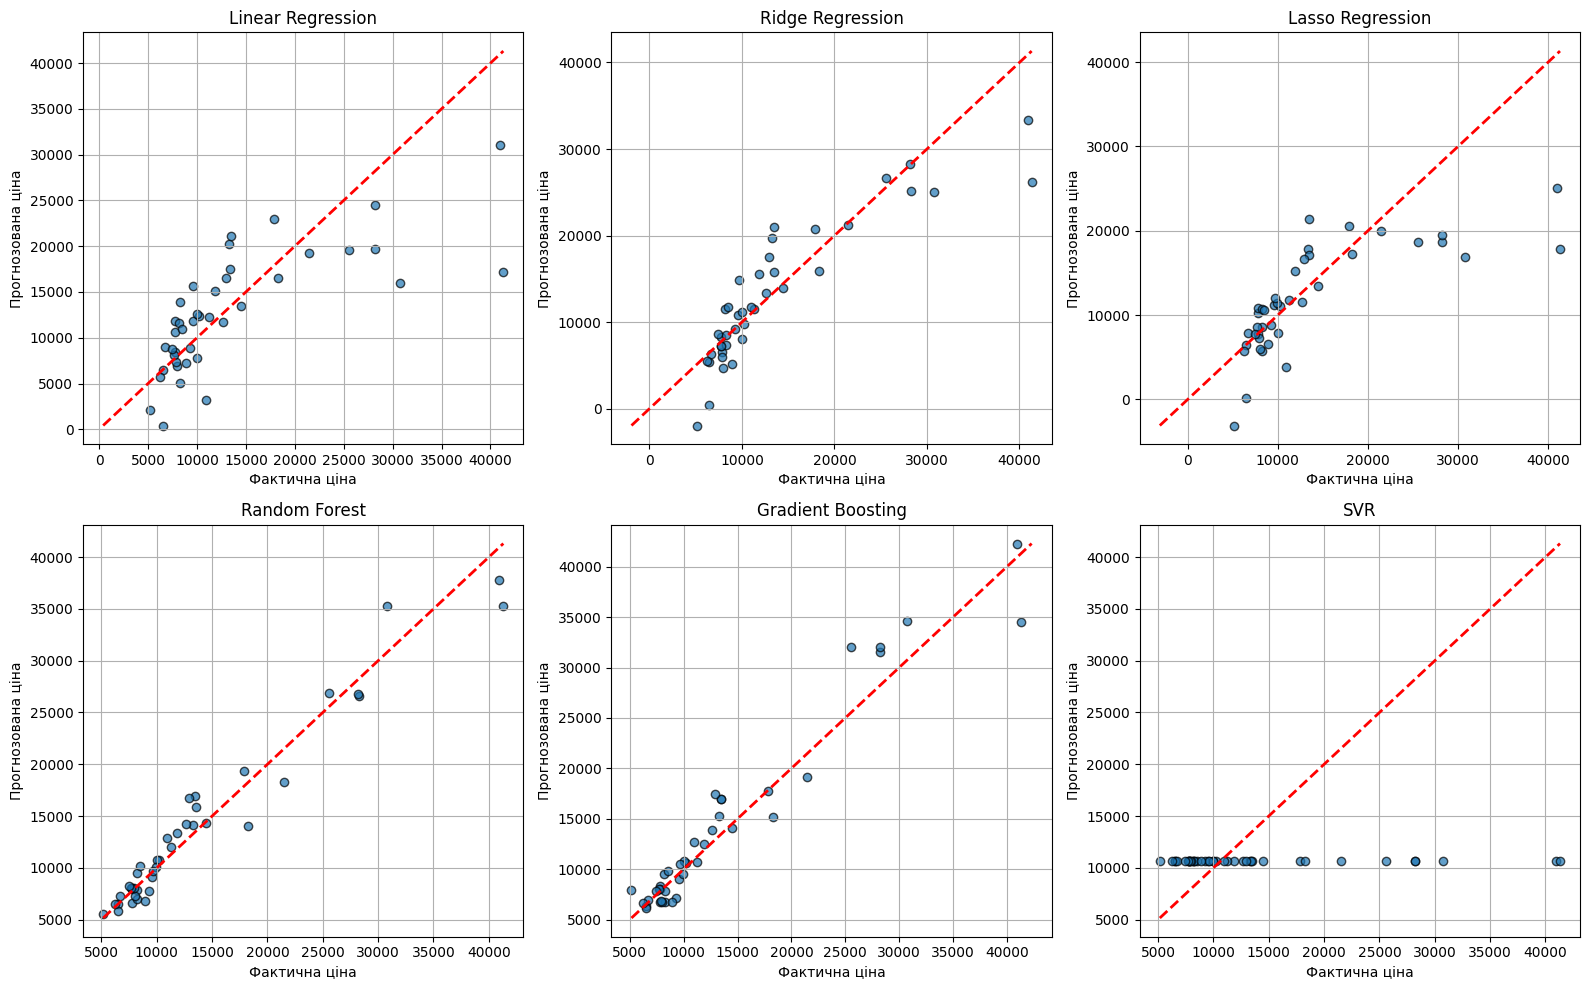

In [14]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 10))
axes = axes.flatten()

for i, (name, pipeline) in enumerate(pipelines.items()):
    y_pred = pipeline.predict(X_test)
    ax = axes[i]

    ax.scatter(y_test, y_pred, alpha=0.7, edgecolors='k')
    min_v, max_v = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
    ax.plot([min_v, max_v], [min_v, max_v], 'r--', lw=2)

    ax.set_title(name)
    ax.set_xlabel('Фактична ціна')
    ax.set_ylabel('Прогнозована ціна')
    ax.grid(True)

plt.tight_layout()
plt.show()

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [15]:
sample_indices = X_test.sample(10, random_state=42).index
sample_X = X_test.loc[sample_indices]
sample_y_true = y_test.loc[sample_indices]
sample_ids = id_test.loc[sample_indices]

sample_y_pred = pipelines['Random Forest'].predict(sample_X)

sample_results = pd.DataFrame({
    'car_ID': sample_ids,
    'Фактична ціна': sample_y_true,
    'Прогнозована ціна': sample_y_pred,
    'Абсолютна помилка': np.abs(sample_y_true - sample_y_pred),
    'MAPE (%)': np.abs((sample_y_true - sample_y_pred) / sample_y_true) * 100
}).reset_index(drop=True)

display(sample_results)

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,MAPE (%)
0,26,6692.0,7298.805,606.805,9.067618
1,176,9988.0,10798.650,810.650,8.116239
2,148,10198.0,10714.570,516.570,5.065405
3,17,41315.0,35310.690,6004.310,14.533003
4,69,28248.0,26595.285,1652.715,5.850733
5,147,7463.0,8230.000,767.000,10.277368
6,144,9960.0,10065.200,105.200,1.056225
7,85,14489.0,14346.480,142.520,0.983643
8,195,12940.0,16765.650,3825.650,29.564529
9,160,7788.0,7995.560,207.560,2.665126


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Висновок:
Емпіричний аналіз показав, що ансамблеві методи (зокрема Random Forest та Gradient Boosting) демонструють найкращі показники якості (R^2 найвищий, а помилки MAE/MSE/MAPE - найменші) завдяки здатності ефективно моделювати нелінійні залежності.
Лінійні моделі (Linear, Ridge, Lasso) також показали прийнятні результати, проте поступаються ансамблям через складніші взаємозв'язки в автомобільній сфері.
Попередня обробка (трансформація Yeo-Johnson, масштабування та боротьба з викидами) суттєво покращила стабільність і якість навчання моделей.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
